In [1]:
%pip install -q gdown

In [2]:
from pathlib import Path
import pandas as pd
import html
import gdown
from pathlib import Path
import unicodedata
from scipy.stats import chisquare, kruskal, spearmanr
import re
import numpy as np
from bs4 import BeautifulSoup
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
!pip install catppuccin
import catppuccin
plt.style.use("mocha")

In [3]:
dataset_path = Path("/content/music_reviews.tsv")

gdown.download(
    id="1V4467Zzfu1S8Gya4oI6Evc0D_rtyb3jX",
    output=str(dataset_path),
    quiet=False,
)

df = pd.read_csv(dataset_path, sep="\t", on_bad_lines="skip")
print("Dataset shape:", df.shape)
df.head()

Downloading...
From (original): https://drive.google.com/uc?id=1V4467Zzfu1S8Gya4oI6Evc0D_rtyb3jX
From (redirected): https://drive.google.com/uc?id=1V4467Zzfu1S8Gya4oI6Evc0D_rtyb3jX&confirm=t&uuid=dc74b8a4-7f0a-4541-bf54-20be5107bd07
To: /content/music_reviews.tsv
100%|██████████| 629M/629M [00:10<00:00, 59.5MB/s]


Dataset shape: (1681484, 15)


,marketplace,customer_id,review_id,product_id,product_parent,product_title,product_category,star_rating,helpful_votes,total_votes,vine,verified_purchase,review_headline,review_body,review_date
0,US,10293599,R14LVB34Z2Z53I,B000YMOQZY,262935067,Knockin' On Heaven's Door,Digital_Music_Purchase,5.0,0.0,0.0,N,Y,favorites,Great rendition. Great song,2015-08-31
1,US,6087195,R2M0R9CWPC82LT,B00ISAEC80,452318038,Flawless,Digital_Music_Purchase,5.0,0.0,0.0,N,Y,Five Stars,A good music to listen.,2015-08-31
2,US,33717063,RQNQI2R3BM52A,B00VBB6AVU,675969129,Scandal of Grace,Digital_Music_Purchase,4.0,0.0,0.0,N,Y,Good,Not as good as the original but I needed to he...,2015-08-31
3,US,14948020,RTUIX1135HUAB,B008A5POJO,282925893,I Surrender (Live),Digital_Music_Purchase,5.0,0.0,0.0,N,Y,Wonderful lyrics! Makes you feel like praying,Time to worship and surrender with this song. ...,2015-08-31
4,US,21694522,RE3QSAT8TL010,B014CW2RN4,109077793,We Are Young (Jersey Club),Digital_Music_Purchase,4.0,0.0,0.0,N,Y,Hot remix but took short,So this should be longer....but love this song:),2015-08-31


In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nMissing values:")
print(df.isnull().sum())

Rows: 1681484
Columns: 15

Missing values:
marketplace            0
customer_id            0
review_id              0
product_id             0
product_parent         0
product_title          0
product_category       0
star_rating            2
helpful_votes          2
total_votes            2
vine                   2
verified_purchase      2
review_headline       59
review_body          114
review_date           76
dtype: int64


## 1. Data Preprocessing

The Amazon Digital Music Purchase Reviews dataset contains **1,681,484 records and 15 original features**.

The following preprocessing steps were performed:

1. **Data Type Conversion:** Converted identifiers to strings, ratings and vote counts to nullable integers, review dates to datetime, and categorical attributes to appropriate data types.
2. **Boolean Transformation:** Converted `verified_purchase` and `vine` values (Y/N) into boolean features (`is_verified` and `is_vine`).
3. **Temporal Feature Extraction:** Extracted `review_year` and `review_month` to support time-based analysis.
4. **Text Feature Extraction:** Created `review_word_count` and `review_char_count` to measure review length.
5. **Helpfulness Ratio:** Calculated the proportion of helpful votes using `helpful_votes / total_votes`, leaving the ratio undefined when total votes equal zero.

### Preprocessing Summary

- **Original Features:** 15
- **New Features:** 7
- **Total Features:** 22
- **Records Retained During Preprocessing:** 1,681,484

Missing values were preserved for the subsequent data cleaning stage. Malformed records encountered during initial TSV import were skipped using `on_bad_lines="skip"`.

These transformations prepare the dataset for data cleaning, exploratory analysis, and statistical testing.

In [5]:
df_preprocessed = df.copy()

print("\nColumn Information:")
df_preprocessed.info()


Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1681484 entries, 0 to 1681483
Data columns (total 15 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   marketplace        1681484 non-null  object 
 1   customer_id        1681484 non-null  int64  
 2   review_id          1681484 non-null  object 
 3   product_id         1681484 non-null  object 
 4   product_parent     1681484 non-null  int64  
 5   product_title      1681484 non-null  object 
 6   product_category   1681484 non-null  object 
 7   star_rating        1681482 non-null  float64
 8   helpful_votes      1681482 non-null  float64
 9   total_votes        1681482 non-null  float64
 10  vine               1681482 non-null  object 
 11  verified_purchase  1681482 non-null  object 
 12  review_headline    1681425 non-null  object 
 13  review_body        1681370 non-null  object 
 14  review_date        1681408 non-null  object 
dtypes: float64(

In [6]:
id_cols = [
    "customer_id", "review_id", "product_id", "product_parent"
]

for cols in id_cols:
    df_preprocessed[cols] = df_preprocessed[cols].astype("string")

df_preprocessed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1681484 entries, 0 to 1681483
Data columns (total 15 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   marketplace        1681484 non-null  object 
 1   customer_id        1681484 non-null  string 
 2   review_id          1681484 non-null  string 
 3   product_id         1681484 non-null  string 
 4   product_parent     1681484 non-null  string 
 5   product_title      1681484 non-null  object 
 6   product_category   1681484 non-null  object 
 7   star_rating        1681482 non-null  float64
 8   helpful_votes      1681482 non-null  float64
 9   total_votes        1681482 non-null  float64
 10  vine               1681482 non-null  object 
 11  verified_purchase  1681482 non-null  object 
 12  review_headline    1681425 non-null  object 
 13  review_body        1681370 non-null  object 
 14  review_date        1681408 non-null  object 
dtypes: float64(3), object(8), string

In [7]:
numeric_cols = [
    "star_rating",
    "helpful_votes",
    "total_votes"
]

for col in numeric_cols:
    df_preprocessed[col] = pd.to_numeric(
        df_preprocessed[col],
        errors="coerce"
    ).astype("Int64")

df_preprocessed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1681484 entries, 0 to 1681483
Data columns (total 15 columns):
 #   Column             Non-Null Count    Dtype 
---  ------             --------------    ----- 
 0   marketplace        1681484 non-null  object
 1   customer_id        1681484 non-null  string
 2   review_id          1681484 non-null  string
 3   product_id         1681484 non-null  string
 4   product_parent     1681484 non-null  string
 5   product_title      1681484 non-null  object
 6   product_category   1681484 non-null  object
 7   star_rating        1681482 non-null  Int64 
 8   helpful_votes      1681482 non-null  Int64 
 9   total_votes        1681482 non-null  Int64 
 10  vine               1681482 non-null  object
 11  verified_purchase  1681482 non-null  object
 12  review_headline    1681425 non-null  object
 13  review_body        1681370 non-null  object
 14  review_date        1681408 non-null  object
dtypes: Int64(3), object(8), string(4)
memory usage: 1

In [8]:
df_preprocessed["review_date"] = pd.to_datetime(
    df_preprocessed["review_date"],
    errors="coerce"
)

In [9]:
for col in ["marketplace", "product_category"]:
    df_preprocessed[col] = df_preprocessed[col].astype("category")

In [10]:
for col in [
    "product_title","review_headline","review_body"
]:
    df_preprocessed[col] = (
        df_preprocessed[col].astype("string")
    )

In [11]:
df_preprocessed["is_verified"] = (
    df_preprocessed["verified_purchase"]
    .map({"Y": True, "N": False})
    .astype("boolean")
)

df_preprocessed["is_vine"] = (
    df_preprocessed["vine"]
    .map({"Y": True, "N": False})
    .astype("boolean")
)

In [12]:
df_preprocessed["review_year"] = (
    df_preprocessed["review_date"].dt.year
)

df_preprocessed["review_month"] = (
    df_preprocessed["review_date"].dt.month
)

In [13]:
df_preprocessed["review_word_count"] = (
    df_preprocessed["review_body"].str.count(r"\S+")
)

df_preprocessed["review_char_count"] = (
    df_preprocessed["review_body"].str.len()
)

In [14]:
df_preprocessed["helpfulness_ratio"] = (
    df_preprocessed["helpful_votes"] /
    df_preprocessed["total_votes"].where(
        df_preprocessed["total_votes"] > 0
    )
)

In [15]:
print(df_preprocessed.shape, "\n")
print(df_preprocessed.info())

(1681484, 22) 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1681484 entries, 0 to 1681483
Data columns (total 22 columns):
 #   Column             Non-Null Count    Dtype         
---  ------             --------------    -----         
 0   marketplace        1681484 non-null  category      
 1   customer_id        1681484 non-null  string        
 2   review_id          1681484 non-null  string        
 3   product_id         1681484 non-null  string        
 4   product_parent     1681484 non-null  string        
 5   product_title      1681484 non-null  string        
 6   product_category   1681484 non-null  category      
 7   star_rating        1681482 non-null  Int64         
 8   helpful_votes      1681482 non-null  Int64         
 9   total_votes        1681482 non-null  Int64         
 10  vine               1681482 non-null  object        
 11  verified_purchase  1681482 non-null  object        
 12  review_headline    1681425 non-null  string        
 13  review_body

In [16]:
df_preprocessed.head()

,marketplace,customer_id,review_id,product_id,product_parent,product_title,product_category,star_rating,helpful_votes,total_votes,...,review_headline,review_body,review_date,is_verified,is_vine,review_year,review_month,review_word_count,review_char_count,helpfulness_ratio
0,US,10293599,R14LVB34Z2Z53I,B000YMOQZY,262935067,Knockin' On Heaven's Door,Digital_Music_Purchase,5,0,0,...,favorites,Great rendition. Great song,2015-08-31,True,False,2015.0,8.0,4,29,<NA>
1,US,6087195,R2M0R9CWPC82LT,B00ISAEC80,452318038,Flawless,Digital_Music_Purchase,5,0,0,...,Five Stars,A good music to listen.,2015-08-31,True,False,2015.0,8.0,5,23,<NA>
2,US,33717063,RQNQI2R3BM52A,B00VBB6AVU,675969129,Scandal of Grace,Digital_Music_Purchase,4,0,0,...,Good,Not as good as the original but I needed to he...,2015-08-31,True,False,2015.0,8.0,22,103,<NA>
3,US,14948020,RTUIX1135HUAB,B008A5POJO,282925893,I Surrender (Live),Digital_Music_Purchase,5,0,0,...,Wonderful lyrics! Makes you feel like praying,Time to worship and surrender with this song. ...,2015-08-31,True,False,2015.0,8.0,15,93,<NA>
4,US,21694522,RE3QSAT8TL010,B014CW2RN4,109077793,We Are Young (Jersey Club),Digital_Music_Purchase,4,0,0,...,Hot remix but took short,So this should be longer....but love this song:),2015-08-31,True,False,2015.0,8.0,8,48,<NA>


In [17]:
df_preprocessed.dtypes

,0
marketplace,category
customer_id,string[python]
review_id,string[python]
product_id,string[python]
product_parent,string[python]
product_title,string[python]
product_category,category
star_rating,Int64
helpful_votes,Int64
total_votes,Int64


# 2. Data Cleaning

Data Cleaning is the process of identifying and correcting or removing inaccurate, incomplete, duplicate, inconsistent, or irrelevant data to improve data quality so that it is ready for model training.

The following data cleaning steps were peformed:


* **Data Quality Assessment** - Examining column data types, missing-value counts, missing-value percentages, and unique-value counts to assess data quality.

* **Duplicate Detection and Removal** - Identifying and removing duplicate records, if any, while retaining the first occurrence.

* **Missing Value Handling and Rating Validation** - Identifying and removing records with missing or blank review text and missing star ratings. Additionally, checking for invalid star ratings outside the valid range of 1–5.

* **HTML Formatting Inspection and Cleaning** - Identifying and removing HTML tags and decoding HTML entities in review text to ensure clean input for sentiment analysis.

* **Final Data Validation** - Performing final quality checks to ensure the cleaned dataset contains valid ratings, non-empty review text, and no exact duplicate records.

Before data cleaning, total records - **1,681,484**

After data cleaning, total recods - **1,681,368**








In [18]:
# Inspecting column data types, missing-value counts, missing-value percentages, and unique-value counts

column_summary = pd.DataFrame({
    "Column": df_preprocessed.columns,
    "Data Type": df_preprocessed.dtypes.values,
    "Missing Count": df_preprocessed.isna().sum().values,
    "Missing %": (
        df_preprocessed.isna().mean().values * 100
    ).round(2),
    "Unique Values": df_preprocessed.nunique().values
})

display(column_summary)

,Column,Data Type,Missing Count,Missing %,Unique Values
0,marketplace,category,0,0.00,1
1,customer_id,string[python],0,0.00,796587
2,review_id,string[python],0,0.00,1681484
3,product_id,string[python],0,0.00,699450
4,product_parent,string[python],0,0.00,644045
5,product_title,string[python],0,0.00,499915
6,product_category,category,0,0.00,3
7,star_rating,Int64,2,0.00,5
8,helpful_votes,Int64,2,0.00,201
9,total_votes,Int64,2,0.00,235


In [19]:
# Identifying exact duplicate rows
print("Exact duplicate rows:", df_preprocessed.duplicated().sum())

# Removing duplicate rows while retaining the first occurrence
rows_before = len(df_preprocessed)

df_preprocessed = df_preprocessed.drop_duplicates(
    keep="first"
).reset_index(drop=True)

# Calculating the number of duplicate rows removed
rows_after = len(df_preprocessed)

print("Duplicate rows removed:", rows_before - rows_after)
print("Remaining rows:", rows_after)

Exact duplicate rows: 0
Duplicate rows removed: 0
Remaining rows: 1681484


In [20]:
# Identifying missing values in review text and star ratings, which are essential for sentiment classification

# Removing records with missing review text or star ratings

rows_before = len(df_preprocessed)

df_preprocessed = df_preprocessed.dropna(
    subset=["review_body", "star_rating"]
).copy()

In [21]:
# Removing records containing only whitespace in the review body

df_preprocessed = df_preprocessed[
    df_preprocessed["review_body"].str.strip().ne("")
].copy()

In [22]:
# Validating star ratings to ensure they are suitable for sentiment labeling and subsequent model evaluation

print(
    df_preprocessed["star_rating"]
    .value_counts(dropna=False)
    .sort_index()
)

star_rating
1      48771
2      24927
3      62149
4     206455
5    1339068
Name: count, dtype: Int64


In [23]:
# Inspecting review text for HTML tags and encoded entities inherited from the original web-based source

TAG = re.compile(
    r"</?[a-z][^>]*>",
    re.IGNORECASE
)

ENTITY = re.compile(
    r"&(?:[a-z][a-z0-9]+|#\d+|#x[0-9a-f]+);",
    re.IGNORECASE
)

review_text = df_preprocessed["review_body"].astype("string")

html_tags = review_text.str.contains(
    TAG,
    na=False
)

html_entities = review_text.str.contains(
    ENTITY,
    na=False
)

print("Reviews containing HTML-like tags:", html_tags.sum())
print("Reviews containing HTML entities:", html_entities.sum())

Reviews containing HTML-like tags: 147426
Reviews containing HTML entities: 89495


In [24]:
# Cleaning review body column from these tags

# Creating a function

def clean_text(value):

    # Handle missing text
    if pd.isna(value):
        return ""

    # Convert to string and decode HTML entities
    text = html.unescape(str(value))

    # Remove HTML tags when detected
    if TAG.search(text):
        text = BeautifulSoup(
            text,
            "html.parser"
        ).get_text(" ")

    # Normalize Unicode
    text = unicodedata.normalize("NFC", text)

    # Replace control characters with spaces
    text = "".join(
        " " if (
            unicodedata.category(char) in ("Cc", "Cf")
            and char not in ("\n", "\t")
        ) else char
        for char in text
    )

    # Remove unnecessary whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [25]:
# Applying cleaning function

df_preprocessed["clean_review"] = (
    df_preprocessed["review_body"]
    .map(clean_text)
)

print("Text cleaning completed successfully!")

# Identify reviews where cleaning made changes
changed_reviews = df_preprocessed[
    df_preprocessed["review_body"].fillna("") !=
    df_preprocessed["clean_review"]
]

print("Total reviews modified:", len(changed_reviews))

Text cleaning completed successfully!
Total reviews modified: 621270


In [26]:
# Identifying reviews that become empty after removing HTML tags and decoding HTML entities

empty_reviews = df_preprocessed[
    df_preprocessed["clean_review"].str.len() == 0
]

print("Total empty reviews:", len(empty_reviews))

display(
    empty_reviews[["review_body", "clean_review"]].head(20)
)

Total empty reviews: 2


,review_body,clean_review
155859,&#60;insert something deep here&#62;,
203638,...,


In [27]:
# Removing missing, empty, or whitespace-only cleaned reviews to ensure valid text inputs for model

rows_before = len(df_preprocessed)

df_preprocessed = df_preprocessed[
    df_preprocessed["clean_review"].notna() &
    df_preprocessed["clean_review"].str.strip().ne("")
].copy()

print("Rows removed:", rows_before - len(df_preprocessed))
print("Remaining rows:", len(df_preprocessed))

Rows removed: 2
Remaining rows: 1681368


Final cleaning validation

In [28]:
# Reset index
df_preprocessed = df_preprocessed.reset_index(drop=True)

# Essential fields must be present
assert df_preprocessed["clean_review"].notna().all()
assert df_preprocessed["star_rating"].notna().all()

# No blank review text
assert df_preprocessed["clean_review"].str.len().gt(0).all()

# Ratings must be valid
assert df_preprocessed["star_rating"].isin(
    [1, 2, 3, 4, 5]
).all()


# No fully duplicated rows
assert df_preprocessed.duplicated().sum() == 0

print("All essential cleaning checks passed!")
print("Final cleaned shape:", df_preprocessed.shape)

All essential cleaning checks passed!
Final cleaned shape: (1681368, 23)


# 3. Exploratory Data Analysis

Before modeling, we explore the cleaned dataset ($1{,}681{,}368$ reviews, $23$ features). We focus on the target we will predict (the star rating) and the input the model will read (the review text).

We answer three questions, each with a different hypothesis test:

| # | Question | Hypothesis test | Effect size |
|---|---|---|---|
| 3.1 | Are star ratings evenly distributed? | Chi-square goodness-of-fit | Cohen's $w$ |
| 3.2 | Does review length differ by rating? | Kruskal–Wallis $H$ test | $\eta^2_H$ |
| 3.3 | Do ratings drift over time? | Spearman rank correlation | $\rho_s$ |

With over $1.6$ million reviews, almost any difference is statistically significant. For every test we therefore also report an effect size, which shows whether the difference actually matters. Each finding leads to a concrete decision for the modeling experiments that follow.

In [29]:
eda = pd.DataFrame({
    "rating": df_preprocessed["star_rating"].astype(int),
    "words":  df_preprocessed["clean_review"].str.count(r"\S+").astype(int),
    "year":   df_preprocessed["review_date"].dt.year,
})

fmt_p = lambda p: "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

print(f"{len(eda):,} reviews | {df_preprocessed.shape[1]} features")

1,681,368 reviews | 23 features


## 3.1 Rating Distribution

The star rating is the variable we will predict, so we first check whether all ratings are equally represented. A **chi-square goodness-of-fit test** compares the observed count of each rating, $O_r$, with the count expected if all five ratings were equally likely, $E_r = N/5$:

$$
\begin{aligned}
H_0 &: p_1 = p_2 = p_3 = p_4 = p_5 = 0.2 \\
H_1 &: \text{at least one } p_r \neq 0.2
\end{aligned}
\qquad \alpha = 0.05
$$

$$
\chi^2 = \sum_{r=1}^{5} \frac{(O_r - E_r)^2}{E_r} \qquad\qquad w = \sqrt{\frac{\chi^2}{N}}
$$

Cohen's $w$ measures how far the distribution is from uniform: $0.1$ is small, $0.3$ is medium, and $0.5$ is large.

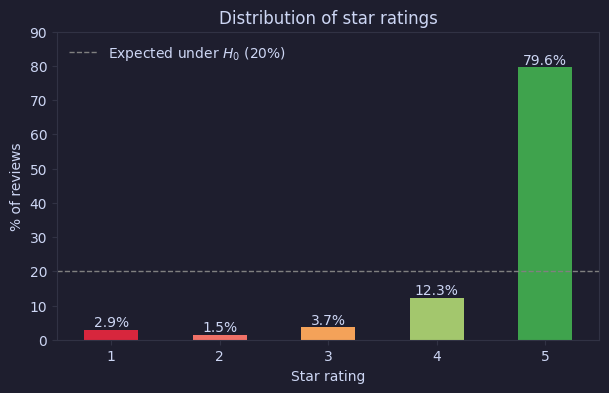

χ² = 3,798,051, p < 0.001, Cohen's w = 1.50 | 5★ : 2★ = 54 : 1


In [30]:
counts = eda["rating"].value_counts().sort_index()
pct = counts / counts.sum() * 100

chi2, p = chisquare(counts)
w = np.sqrt(chi2 / counts.sum())

colors = ["#D7263D", "#F07167", "#F4A259", "#A3C76D", "#3FA34D"]  # for more visually intuitive colors
ax = pct.plot(kind="bar", color=colors, rot=0, figsize=(7, 4))
ax.bar_label(ax.containers[0], fmt="%.1f%%")
expected = ax.axhline(20, color="gray", linestyle="--", linewidth=1, label="Expected under $H_0$ (20%)")
ax.set(title="Distribution of star ratings", xlabel="Star rating", ylabel="% of reviews", ylim=(0, 90))
ax.legend(handles=[expected], frameon=False)
plt.show()

print(f"χ² = {chi2:,.0f}, {fmt_p(p)}, Cohen's w = {w:.2f} | 5★ : 2★ = {counts[5] / counts[2]:.0f} : 1")

### Conclusion 1: The ratings are heavily imbalanced, so we group them into three classes.

First, we reject $H_0$ ($\chi^2 \approx 3.8 \times 10^6$, $p < 0.001$). Cohen's $w \approx 1.50$ is three times the threshold for a large effect, so the ratings are far from uniform.

As we can see from the plot above, $79.6\%$ of reviews are 5★, while 2★ makes up only $1.5\%$, a ratio of about $54 : 1$. We can also observe that the distribution is J-shaped. This pattern is typical of online reviews, where people are more likely to write when they love or dislike something than when they feel lukewarm.

Classes this small (like 1, 2, and 3-starred reviews) are hard for a model to learn. We propose merging neighbouring ratings into three sentiment classes: `Bad` (1–2★, $4.4\%$), `Good` (3–4★, $16.0\%$), and `Excellent` (5★, $79.6\%$). The grouping reduces the imbalance from $54 : 1$ to about $18 : 1$. However, even after grouping, a model that always predicts *Excellent* would be $79.6\%$ accurate. The split must therefore be stratified by class, and performance measured with `macro-F1` rather than accuracy.

## 3.2 Review Length by Rating

The review text is what the model will read, so we check how long reviews are and whether length differs between ratings. Before choosing a test, we check the shape of the length distribution.

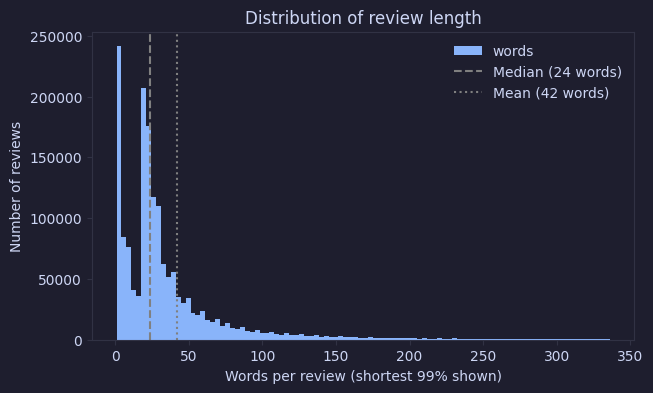

Mean: 42 words | Median: 24 words | Skewness: 17.7


In [32]:
words = eda["words"]
mean, median, skew = words.mean(), words.median(), words.skew()

ax = words[words <= words.quantile(0.99)].plot(kind="hist", bins=100, figsize=(7, 4)) # histogram so that we can see the distribution
ax.axvline(median, color="gray", linestyle="--", linewidth=1.5, label=f"Median ({median:.0f} words)")
ax.axvline(mean, color="gray", linestyle=":", linewidth=1.5, label=f"Mean ({mean:.0f} words)")
ax.set(title="Distribution of review length", xlabel="Words per review (shortest 99% shown)", ylabel="Number of reviews")
ax.legend(frameon=False)
plt.show()

print(f"Mean: {mean:.0f} words | Median: {median:.0f} words | Skewness: {skew:.1f}")

As the histogram shows, most reviews are short, but a long tail stretches to the right and pulls the mean above the median. The skewness is far above $1$, so review lengths are heavily right-skewed. This makes `ANOVA` unreliable. Instead we use the `Kruskal–Wallis H test`, a rank-based alternative to one-way ANOVA that compares the five rating groups without assuming normality:

$$
\begin{aligned}
H_0 &: \text{review length has the same distribution for every rating} \\
H_1 &: \text{at least one rating differs}
\end{aligned}
\qquad \alpha = 0.05
$$

$$
H = \frac{12}{N(N+1)} \sum_{r=1}^{5} \frac{R_r^2}{n_r} - 3(N+1) \qquad\qquad \eta^2_H = \frac{H - k + 1}{N - k}
$$

Here, $R_r$ is the sum of ranks in rating group $r$, $n_r$ is the size of that group, and $k = 5$ is the number of groups. For $\eta^2_H$, $0.01$ is small, $0.06$ is medium, and $0.14$ is large.

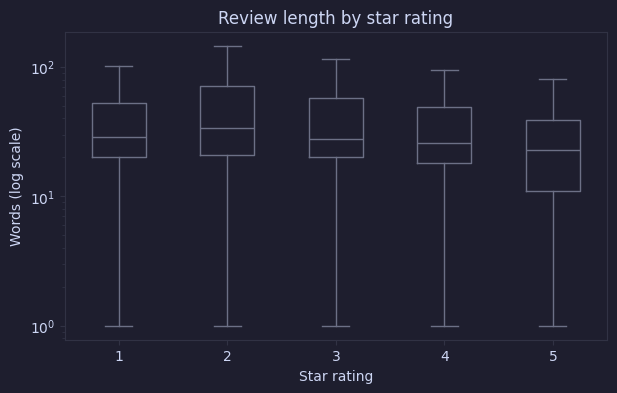

H = 18,006, p < 0.001, η² = 0.011
Median words by rating: {1: 29, 2: 34, 3: 28, 4: 26, 5: 23}
Overall median: 24 words | 95th percentile: 133 words


In [33]:
groups = [eda.loc[eda["rating"] == r, "words"] for r in range(1, 6)]
H, p = kruskal(*groups)
eta2 = (H - 5 + 1) / (len(eda) - 5)

fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot(groups, showfliers=False)
ax.set_yscale("log")
ax.set(title="Review length by star rating", xlabel="Star rating", ylabel="Words (log scale)")
plt.show()

print(f"H = {H:,.0f}, {fmt_p(p)}, η² = {eta2:.3f}")
print("Median words by rating:", eda.groupby("rating")["words"].median().astype(int).to_dict())
print(f"Overall median: {eda['words'].median():.0f} words | 95th percentile: {eda['words'].quantile(0.95):.0f} words")

### Conclusion 2: Reviews are short, and length differs only slightly by rating

We reject $H_0$ ($H = 18{,}006$, $p < 0.001$), but the effect is small ($\eta^2_H = 0.011$). The rating accounts for only about $1\%$ of the variation in review length. The length distributions overlap heavily, so length alone says little about the rating. The model will have to rely on what the review actually says.

For our further experiments, it's worth noting that the median review has only $24$ words, and $95\%$ of reviews have at most $133$ words. A maximum input length of $256$ tokens will therefore fit almost every review without truncation.

## 3.3 Rating Trend Over Time

The reviews span many years. If ratings drift over time, a split by date would give training and test sets with different class mixes. We test for a monotonic trend between review year $Y$ and star rating $R$ with **Spearman's rank correlation**, which works on ranks and therefore suits two ordinal variables. Only years with at least $1{,}000$ reviews are included.

$$
\rho_s = \operatorname{corr}\big(\operatorname{rank}(Y),\ \operatorname{rank}(R)\big)
$$

$$
\begin{aligned}
H_0 &: \rho_s = 0 \quad \text{(no trend)} \\
H_1 &: \rho_s \neq 0
\end{aligned}
\qquad \alpha = 0.05
$$

For $|\rho_s|$, values below $0.1$ are negligible, $0.1$ to $0.3$ weak, $0.3$ to $0.5$ moderate, and above $0.5$ strong.

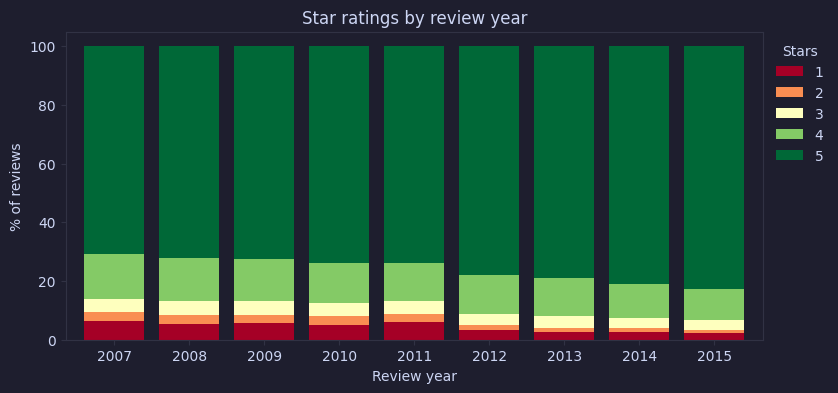

Spearman ρ = 0.063, p < 0.001 | 1,681,247 reviews across 9 years
5★ share: lowest 70.7% (2007), highest 82.7% (2015)


In [34]:
counts = eda["year"].value_counts()
dated = eda[eda["year"].isin(counts[counts >= 1000].index)].astype({"year": int})

rho, p = spearmanr(dated["year"], dated["rating"])

shares = pd.crosstab(dated["year"], dated["rating"], normalize="index") * 100
ax = shares.plot(kind="bar", stacked=True, colormap="RdYlGn", rot=0, width=0.8, figsize=(9, 4))
ax.set(title="Star ratings by review year", xlabel="Review year", ylabel="% of reviews")
ax.legend(title="Stars", frameon=False, bbox_to_anchor=(1, 1))
plt.show()

print(f"Spearman ρ = {rho:.3f}, {fmt_p(p)} | {len(dated):,} reviews across {dated['year'].nunique()} years")
print(f"5★ share: lowest {shares[5].min():.1f}% ({shares[5].idxmin()}), highest {shares[5].max():.1f}% ({shares[5].idxmax()})")

### Conclusion 3: Ratings become slightly more positive over time

We reject $H_0$ ($\rho_s = 0.063$, $p < 0.001$), but the trend is negligible in strength, since $|\rho_s| < 0.1$. Almost all reviews ($1{,}681{,}247$ of $1{,}681{,}368$) were written between 2007 and 2015. Over this period, the share of 5★ reviews rises from $70.7\%$ in 2007 to $82.7\%$ in 2015, and 1★ and 2★ reviews become rarer, with most of the shift happening after 2011. Because the class mix changes from year to year, a split by date would give training and test sets with different class proportions. We therefore split the data randomly, stratified by class, so that every subset covers the same years.

## 3.4 Conclusion

We explored the dataset with three different statistical tests, each paired with an effect size and a plot: a chi-square goodness-of-fit test for the rating distribution, a Kruskal–Wallis $H$ test for review length across ratings, and a Spearman rank correlation for the trend in ratings over time. With over $1.6$ million reviews, all three tests are significant, so the effect sizes decide which findings actually matter.

| Test | Finding | Effect size | Decision |
|---|---|---|---|
| Chi-square goodness-of-fit | Ratings are far from uniform: $79.6\%$ are 5★ | $w = 1.50$ (large) | Three classes, stratified split, macro-F1 |
| Kruskal–Wallis $H$ | Length differs slightly by rating; median $24$ words | $\eta^2_H = 0.011$ (small) | Maximum input length of $256$ tokens |
| Spearman correlation | Ratings drift upward over time | $\rho_s = 0.063$ (negligible) | Random split instead of a split by date |